### Machine Learning Supervised Algorithms

#### Keith R. Holdaway FGS

### Caveats

#### Neural Network Issues:

Poor hyperparameter tuning

Insufficient training or convergence problems

Scaling issues despite using scaled data

#### Ensemble Issues:

The ensemble is combining poorly performing models (especially the Neural Network)

Voting regressor with bad models can amplify errors

No weighting of models based on performance

Improved Petrophysical Machine Learning Demonstration
Generated dataset with 2000 samples
Training set size: 1600
Test set size: 400
Target range: 0.010 - 0.350

Training and evaluating models...

Training Linear Regression...
Linear Regression - R²: 0.9088, RMSE: 0.0154

Training Decision Tree...
Decision Tree - R²: 0.6785, RMSE: 0.0288

Training Random Forest...
Random Forest - R²: 0.8474, RMSE: 0.0199

Training Gradient Boosting...
Gradient Boosting - R²: 0.8852, RMSE: 0.0172

Training SVM...
SVM - R²: 0.4415, RMSE: 0.0380

Training Neural Network...
Neural Network - R²: 0.7483, RMSE: 0.0255

Creating ensemble from successful models: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM', 'Neural Network']
Created ensemble with: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM', 'Neural Network']
Ensemble - R²: 0.8156, RMSE: 0.0218

MODEL PERFORMANCE DIAGNOSIS

Data Statistics:
Target mean: 0.1481
Target std: 0.0495
Featur

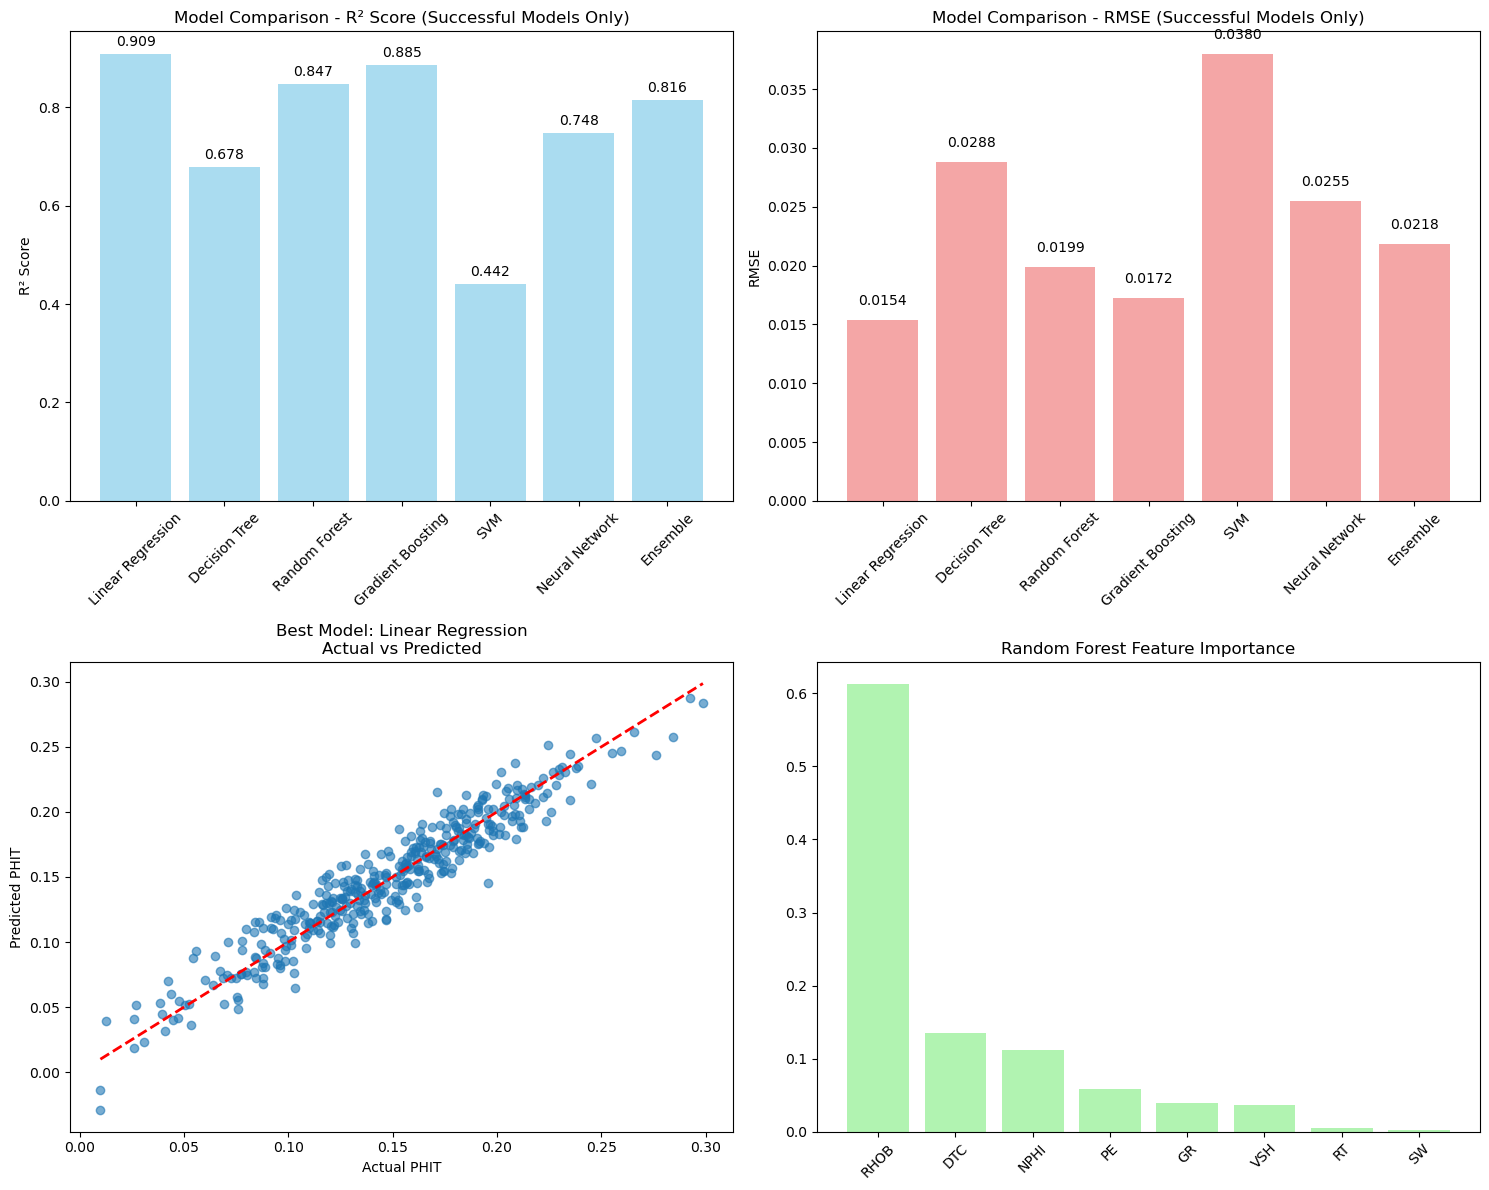


IMPROVED PETROPHYSICAL ML - SUCCESSFUL MODELS REPORT

SUCCESSFUL MODEL PERFORMANCE SUMMARY:
            Model     R²   RMSE    MAE  CV R² Mean  CV R² Std
Linear Regression 0.9088 0.0154 0.0122      0.9089     0.0074
    Decision Tree 0.6785 0.0288 0.0230      0.6685     0.0213
    Random Forest 0.8474 0.0199 0.0161      0.8324     0.0114
Gradient Boosting 0.8852 0.0172 0.0136      0.8765     0.0087
              SVM 0.4415 0.0380 0.0296      0.4208     0.0119
   Neural Network 0.7483 0.0255 0.0197      0.6069     0.0957
         Ensemble 0.8156 0.0218 0.0171      0.7927     0.0115

BEST PERFORMING MODEL: Linear Regression
R² Score: 0.9088

Demonstration completed!


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

class ImprovedPetrophysicalMLDemo:
    def __init__(self):
        self.data = None
        self.X_train = None
        self.X_test = None
        self.y_train = None
        self.y_test = None
        self.scaler = StandardScaler()
        self.models = {}
        self.results = {}
        
    def generate_petrophysical_data(self, n_samples=2000):  # Increased samples
        """
        Generate realistic petrophysical data for demonstration
        """
        np.random.seed(42)
        
        # Generate realistic ranges for common well logs
        data = {
            'DEPTH': np.arange(n_samples),
            'GR': np.random.normal(75, 25, n_samples),
            'RT': np.random.lognormal(2, 0.8, n_samples),  # Reduced variance
            'NPHI': np.random.normal(0.15, 0.04, n_samples),  # Reduced noise
            'RHOB': np.random.normal(2.4, 0.15, n_samples),   # Reduced noise
            'DTC': np.random.normal(85, 12, n_samples),       # Reduced noise
            'PE': np.random.normal(3.0, 0.8, n_samples)       # Reduced noise
        }
        
        # Create more realistic porosity relationship
        dt_porosity = (data['DTC'] - 55) / (189 - 55)
        density_porosity = (2.65 - data['RHOB']) / (2.65 - 1.0)
        neutron_porosity = data['NPHI']
        
        # Combine porosities with realistic weights
        true_porosity = (0.4 * density_porosity + 0.4 * neutron_porosity + 0.2 * dt_porosity)
        
        # Add lithology effects
        shale_effect = (data['GR'] - 30) / 150 * 0.08  # Reduced effect
        dolomite_effect = (data['PE'] - 2.5) * 0.015   # Reduced effect
        
        # Reduced noise
        data['PHIT'] = true_porosity - shale_effect + dolomite_effect + np.random.normal(0, 0.015, n_samples)
        data['PHIT'] = np.clip(data['PHIT'], 0.01, 0.35)
        
        # Add VSH (Volume of Shale)
        gr_min, gr_max = 30, 150
        data['VSH'] = (data['GR'] - gr_min) / (gr_max - gr_min)
        data['VSH'] = np.clip(data['VSH'], 0, 1)
        
        # Add SW (Water Saturation)
        data['SW'] = (0.62 / (data['RT'] * (data['PHIT']**2))) ** 0.5
        data['SW'] = np.clip(data['SW'], 0.1, 1.0)
        
        self.data = pd.DataFrame(data)
        return self.data
    
    def prepare_data(self, target='PHIT', test_size=0.2):
        """
        Prepare data for machine learning with better validation
        """
        feature_columns = ['GR', 'RT', 'NPHI', 'RHOB', 'DTC', 'PE', 'VSH', 'SW']
        X = self.data[feature_columns]
        y = self.data[target]
        
        # Split the data
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=test_size, random_state=42
        )
        
        # Scale the features
        self.X_train_scaled = self.scaler.fit_transform(self.X_train)
        self.X_test_scaled = self.scaler.transform(self.X_test)
        
        print(f"Training set size: {len(self.X_train)}")
        print(f"Test set size: {len(self.X_test)}")
        print(f"Target range: {y.min():.3f} - {y.max():.3f}")
        
        return self.X_train, self.X_test, self.y_train, self.y_test
    
    def optimize_neural_network(self):
        """
        Optimize neural network hyperparameters
        """
        print("Optimizing Neural Network hyperparameters...")
        
        param_grid = {
            'hidden_layer_sizes': [(50, 25), (100, 50), (50,), (100,)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.0001, 0.001, 0.01],
            'learning_rate_init': [0.001, 0.01],
            'max_iter': [1000, 2000]
        }
        
        nn = MLPRegressor(random_state=42, early_stopping=True, validation_fraction=0.1)
        
        # Use smaller grid search for demonstration
        grid_search = GridSearchCV(
            nn, param_grid, cv=3, scoring='r2', n_jobs=-1, 
            verbose=0  # Set to 1 for more details
        )
        
        grid_search.fit(self.X_train_scaled, self.y_train)
        
        print(f"Best NN parameters: {grid_search.best_params_}")
        print(f"Best NN CV score: {grid_search.best_score_:.4f}")
        
        return grid_search.best_estimator_
    
    def initialize_models(self):
        """
        Initialize all ML models with improved parameters
        """
        # Basic models with better parameters
        self.models = {
            'Linear Regression': LinearRegression(),
            'Decision Tree': DecisionTreeRegressor(random_state=42, max_depth=6, min_samples_split=10),
            'Random Forest': RandomForestRegressor(n_estimators=150, random_state=42, max_depth=8, min_samples_split=10),
            'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, random_state=42, max_depth=4, learning_rate=0.1),
            'SVM': SVR(kernel='rbf', C=10.0, gamma='scale', epsilon=0.1),
        }
        
        # Optimize Neural Network
        self.models['Neural Network'] = MLPRegressor(
            hidden_layer_sizes=(100, 50),
            activation='relu',
            solver='adam',
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=2000,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42
        )
        
        return self.models
    
    def create_ensemble(self, top_models=None):
        """
        Create ensemble only from well-performing models
        """
        if top_models is None:
            # Use models that typically perform well
            top_models = ['Random Forest', 'Gradient Boosting', 'Linear Regression']
        
        ensemble_estimators = [(name, self.models[name]) for name in top_models]
        self.models['Ensemble'] = VotingRegressor(estimators=ensemble_estimators)
        
        print(f"Created ensemble with: {top_models}")
    
    def train_and_evaluate_models(self):
        """
        Train all models and evaluate their performance with better handling
        """
        self.results = {}
        
        # First pass: train all basic models
        for name, model in self.models.items():
            if name == 'Ensemble':
                continue  # Train ensemble separately
                
            print(f"\nTraining {name}...")
            
            # Use scaled data for SVM and Neural Network
            if name in ['SVM', 'Neural Network']:
                X_train_used = self.X_train_scaled
                X_test_used = self.X_test_scaled
            else:
                X_train_used = self.X_train
                X_test_used = self.X_test
            
            try:
                # Train model
                model.fit(X_train_used, self.y_train)
                
                # Make predictions
                y_pred = model.predict(X_test_used)
                
                # Calculate metrics
                mse = mean_squared_error(self.y_test, y_pred)
                rmse = np.sqrt(mse)
                mae = mean_absolute_error(self.y_test, y_pred)
                r2 = r2_score(self.y_test, y_pred)
                
                # Cross-validation scores
                cv_scores = cross_val_score(model, X_train_used, self.y_train, 
                                          cv=5, scoring='r2')
                
                self.results[name] = {
                    'model': model,
                    'predictions': y_pred,
                    'mse': mse,
                    'rmse': rmse,
                    'mae': mae,
                    'r2': r2,
                    'cv_mean': cv_scores.mean(),
                    'cv_std': cv_scores.std(),
                    'trained_successfully': True
                }
                
                print(f"{name} - R²: {r2:.4f}, RMSE: {rmse:.4f}")
                
            except Exception as e:
                print(f"Error training {name}: {e}")
                self.results[name] = {
                    'trained_successfully': False,
                    'r2': -np.inf  # Mark as failed
                }
        
        # Create ensemble only from successful models
        successful_models = [name for name, result in self.results.items() 
                           if result.get('trained_successfully', False) and result['r2'] > 0]
        
        if len(successful_models) >= 2:
            print(f"\nCreating ensemble from successful models: {successful_models}")
            self.create_ensemble(successful_models)
            
            # Train ensemble
            ensemble_model = self.models['Ensemble']
            ensemble_model.fit(self.X_train, self.y_train)  # Use unscaled for ensemble
            
            y_pred_ensemble = ensemble_model.predict(self.X_test)
            
            # Calculate ensemble metrics
            mse_ensemble = mean_squared_error(self.y_test, y_pred_ensemble)
            rmse_ensemble = np.sqrt(mse_ensemble)
            mae_ensemble = mean_absolute_error(self.y_test, y_pred_ensemble)
            r2_ensemble = r2_score(self.y_test, y_pred_ensemble)
            
            cv_scores_ensemble = cross_val_score(ensemble_model, self.X_train, self.y_train, 
                                               cv=5, scoring='r2')
            
            self.results['Ensemble'] = {
                'model': ensemble_model,
                'predictions': y_pred_ensemble,
                'mse': mse_ensemble,
                'rmse': rmse_ensemble,
                'mae': mae_ensemble,
                'r2': r2_ensemble,
                'cv_mean': cv_scores_ensemble.mean(),
                'cv_std': cv_scores_ensemble.std(),
                'trained_successfully': True
            }
            
            print(f"Ensemble - R²: {r2_ensemble:.4f}, RMSE: {rmse_ensemble:.4f}")
        else:
            print("Not enough successful models to create ensemble")
            self.results['Ensemble'] = {'trained_successfully': False}
        
        return self.results
    
    def diagnose_issues(self):
        """
        Diagnose potential issues with model performance
        """
        print("\n" + "="*50)
        print("MODEL PERFORMANCE DIAGNOSIS")
        print("="*50)
        
        # Check data quality
        print(f"\nData Statistics:")
        print(f"Target mean: {self.y_train.mean():.4f}")
        print(f"Target std: {self.y_train.std():.4f}")
        print(f"Feature means: {self.X_train.mean().values}")
        
        # Check for successful models
        successful_models = [name for name, result in self.results.items() 
                           if result.get('trained_successfully', False) and result['r2'] > 0]
        failed_models = [name for name in self.results if name not in successful_models]
        
        print(f"\nSuccessful models (R² > 0): {successful_models}")
        print(f"Models with issues: {failed_models}")
        
        # Specific NN diagnosis
        if 'Neural Network' in self.results and self.results['Neural Network'].get('trained_successfully', False):
            nn_result = self.results['Neural Network']
            if nn_result['r2'] < 0:
                print("\nNeural Network Issues:")
                print("- May need more training data")
                print("- Try different architecture")
                print("- Check learning rate and regularization")
                print("- Consider using early stopping")
    
    def plot_comparison(self):
        """
        Create comparison plots of model performances
        """
        # Filter only successful models
        successful_results = {name: result for name, result in self.results.items() 
                            if result.get('trained_successfully', False) and result['r2'] > 0}
        
        if not successful_results:
            print("No successful models to plot")
            return
            
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        
        models_list = list(successful_results.keys())
        r2_scores = [successful_results[model]['r2'] for model in models_list]
        rmse_scores = [successful_results[model]['rmse'] for model in models_list]
        
        # R² comparison
        bars = axes[0,0].bar(models_list, r2_scores, color='skyblue', alpha=0.7)
        axes[0,0].set_title('Model Comparison - R² Score (Successful Models Only)')
        axes[0,0].set_ylabel('R² Score')
        axes[0,0].tick_params(axis='x', rotation=45)
        
        # Add value labels on bars
        for bar, value in zip(bars, r2_scores):
            axes[0,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                          f'{value:.3f}', ha='center', va='bottom')
        
        # RMSE comparison
        bars = axes[0,1].bar(models_list, rmse_scores, color='lightcoral', alpha=0.7)
        axes[0,1].set_title('Model Comparison - RMSE (Successful Models Only)')
        axes[0,1].set_ylabel('RMSE')
        axes[0,1].tick_params(axis='x', rotation=45)
        
        for bar, value in zip(bars, rmse_scores):
            axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, 
                          f'{value:.4f}', ha='center', va='bottom')
        
        # Predictions vs Actual for best model
        best_model = max(successful_results.items(), key=lambda x: x[1]['r2'])[0]
        y_pred_best = successful_results[best_model]['predictions']
        
        axes[1,0].scatter(self.y_test, y_pred_best, alpha=0.6)
        axes[1,0].plot([self.y_test.min(), self.y_test.max()], 
                      [self.y_test.min(), self.y_test.max()], 'r--', lw=2)
        axes[1,0].set_xlabel('Actual PHIT')
        axes[1,0].set_ylabel('Predicted PHIT')
        axes[1,0].set_title(f'Best Model: {best_model}\nActual vs Predicted')
        
        # Feature importance for tree-based models
        if 'Random Forest' in successful_results:
            rf_model = self.models['Random Forest']
            if hasattr(rf_model, 'feature_importances_'):
                feature_importance = rf_model.feature_importances_
                feature_names = self.X_train.columns
                indices = np.argsort(feature_importance)[::-1]
                
                axes[1,1].bar(range(len(feature_importance)), 
                             feature_importance[indices],
                             color='lightgreen', alpha=0.7)
                axes[1,1].set_title('Random Forest Feature Importance')
                axes[1,1].set_xticks(range(len(feature_importance)))
                axes[1,1].set_xticklabels([feature_names[i] for i in indices], rotation=45)
        
        plt.tight_layout()
        plt.savefig('improved_petrophysical_ml_comparison.png', dpi=300, bbox_inches='tight')
        plt.show()

def main():
    """
    Main function to run the improved petrophysical ML demonstration
    """
    print("Improved Petrophysical Machine Learning Demonstration")
    print("="*60)
    
    # Initialize and run the demonstration
    demo = ImprovedPetrophysicalMLDemo()
    
    # Generate data with less noise
    data = demo.generate_petrophysical_data(n_samples=2000)
    print(f"Generated dataset with {len(data)} samples")
    
    # Prepare data for ML
    demo.prepare_data()
    
    # Initialize models with better parameters
    demo.initialize_models()
    
    # Train and evaluate models
    print("\nTraining and evaluating models...")
    results = demo.train_and_evaluate_models()
    
    # Diagnose any issues
    demo.diagnose_issues()
    
    # Generate plots and report
    demo.plot_comparison()
    
    # Generate comprehensive report
    successful_results = {name: result for name, result in results.items() 
                        if result.get('trained_successfully', False) and result['r2'] > 0}
    
    if successful_results:
        print("\n" + "="*80)
        print("IMPROVED PETROPHYSICAL ML - SUCCESSFUL MODELS REPORT")
        print("="*80)
        
        results_df = pd.DataFrame({
            'Model': list(successful_results.keys()),
            'R²': [successful_results[model]['r2'] for model in successful_results],
            'RMSE': [successful_results[model]['rmse'] for model in successful_results],
            'MAE': [successful_results[model]['mae'] for model in successful_results],
            'CV R² Mean': [successful_results[model]['cv_mean'] for model in successful_results],
            'CV R² Std': [successful_results[model]['cv_std'] for model in successful_results]
        }).round(4)
        
        print("\nSUCCESSFUL MODEL PERFORMANCE SUMMARY:")
        print(results_df.to_string(index=False))
        
        best_model = max(successful_results.items(), key=lambda x: x[1]['r2'])[0]
        print(f"\nBEST PERFORMING MODEL: {best_model}")
        print(f"R² Score: {successful_results[best_model]['r2']:.4f}")
    
    print("\nDemonstration completed!")

if __name__ == "__main__":
    main()

### Linear Regression

#### The Mathematical "Trend Line"
Linear regression finds the best-fitting straight line through your data using this equation:

PHIT = m × RHOB + b

#### Where:

PHIT = What we want to predict (dependent variable)

RHOB = What we use to make the prediction (independent variable)

m = Slope of the line (how much PHIT changes with RHOB)

b = Intercept (the PHIT value when RHOB is zero)

#### How It Finds the "Best" Line
The algorithm tries every possible line and chooses the one that minimizes the total distance between the line and all data points. It's like optimizing this relationship:

Total Error = ∑(Actual PHIT - Predicted PHIT)²

It finds the m and b that make this total error as small as possible.

#### Real Petrophysical Example
Let's say we want to predict Porosity (PHIT) from Sonic Log (DTC) using the Wyllie time-average equation:

#### Traditional Approach:

PHIT = (Δt - Δt_ma) / (Δt_fluid - Δt_ma)

#### Linear Regression Approach:

PHIT = β₀ + β₁ × DTC

#### Where:

β₁ represents the relationship between DTC and porosity

β₀ accounts for the matrix transit time

#### Multiple Linear Regression in Petrophysics
In reality, you rarely use just one log. Linear regression can handle multiple inputs:

PHIT = β₀ + β₁×DTC + β₂×RHOB + β₃×NPHI + β₄×GR

This is like creating a multi-dimensional trend that considers all logs simultaneously!

#### Practical Example: Porosity Prediction

=== LINEAR REGRESSION DEMONSTRATION FOR PETROPHYSICISTS ===
Dataset: 500 depth points
PHIT range: 0.050 - 0.340
RHOB range: 1.861 - 2.926

=== LINEAR REGRESSION RESULTS ===
Regression equation: PHIT = 0.7214 + -0.2304 * RHOB
R² score: 0.6453 (64.5% of variance explained)
Slope: -0.2304 → For every 1 g/cc increase in RHOB, PHIT changes by -0.2304
Intercept: 0.7214 → Theoretical PHIT when RHOB = 0


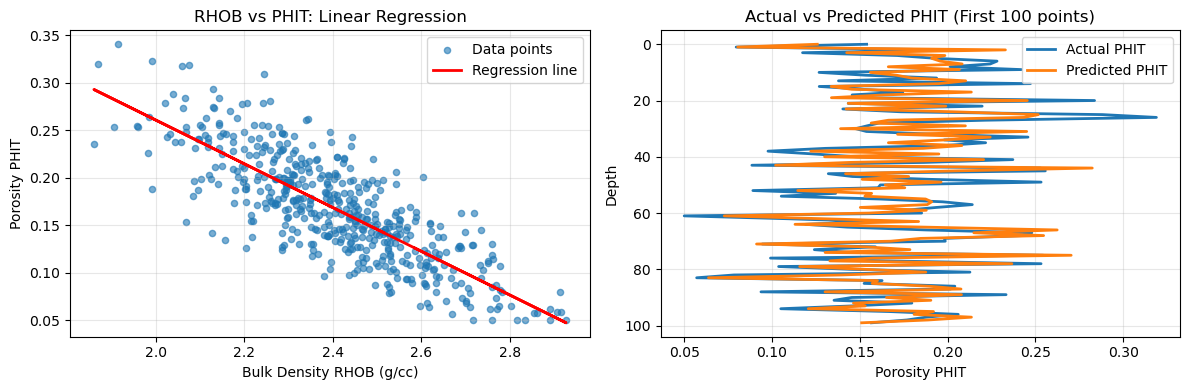


=== MULTIPLE LINEAR REGRESSION ===
Using: GR, RHOB, DTC, NPHI to predict PHIT
Multiple regression R²: 0.8830 (88.3% of variance explained)

Regression equation:
PHIT = 0.5606 + 
       -0.000001 * GR + 
       -0.2367 * RHOB + 
       0.001399 * DTC + 
       0.3615 * NPHI

Coefficient interpretation:
GR:    -0.000001 → Effect of Gamma Ray on porosity
RHOB:  -0.2367 → Effect of Bulk Density on porosity
DTC:   0.001399 → Effect of Sonic on porosity
NPHI:  0.3615 → Effect of Neutron Porosity on porosity

Using multiple logs improves R² by +36.8%


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Simulate realistic petrophysical data
np.random.seed(42)
n_samples = 500

# Generate synthetic well log data
GR = np.random.normal(75, 25, n_samples)        # Gamma Ray (API)
RHOB = np.random.normal(2.4, 0.2, n_samples)    # Bulk Density (g/cc)
DTC = np.random.normal(85, 15, n_samples)       # Sonic (us/ft)
NPHI = np.random.normal(0.15, 0.05, n_samples)  # Neutron Porosity

# Create porosity using a linear combination (plus some noise)
PHIT = (0.4 * ((2.65 - RHOB) / 1.65) + 
        0.4 * NPHI + 
        0.2 * ((DTC - 55) / 134) +
        np.random.normal(0, 0.02, n_samples))

# Ensure realistic porosity bounds
PHIT = np.clip(PHIT, 0.05, 0.35)

print("=== LINEAR REGRESSION DEMONSTRATION FOR PETROPHYSICISTS ===")
print(f"Dataset: {n_samples} depth points")
print(f"PHIT range: {PHIT.min():.3f} - {PHIT.max():.3f}")
print(f"RHOB range: {RHOB.min():.3f} - {RHOB.max():.3f}")

# Create a simple linear regression: Predict PHIT from RHOB only
# Reshape for sklearn (it expects 2D array for features)
RHOB_2d = RHOB.reshape(-1, 1)

# Create and train the linear regression model
model = LinearRegression()
model.fit(RHOB_2d, PHIT)

# Make predictions
PHIT_pred = model.predict(RHOB_2d)

# Get the coefficients
slope = model.coef_[0]
intercept = model.intercept_
r2 = r2_score(PHIT, PHIT_pred)

print(f"\n=== LINEAR REGRESSION RESULTS ===")
print(f"Regression equation: PHIT = {intercept:.4f} + {slope:.4f} * RHOB")
print(f"R² score: {r2:.4f} ({(r2*100):.1f}% of variance explained)")
print(f"Slope: {slope:.4f} → For every 1 g/cc increase in RHOB, PHIT changes by {slope:.4f}")
print(f"Intercept: {intercept:.4f} → Theoretical PHIT when RHOB = 0")

# Plot the results
plt.figure(figsize=(12, 4))

# Plot 1: Crossplot with regression line
plt.subplot(1, 2, 1)
plt.scatter(RHOB, PHIT, alpha=0.6, s=20, label='Data points')
plt.plot(RHOB, PHIT_pred, color='red', linewidth=2, label='Regression line')
plt.xlabel('Bulk Density RHOB (g/cc)')
plt.ylabel('Porosity PHIT')
plt.title('RHOB vs PHIT: Linear Regression')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Depth track comparison
plt.subplot(1, 2, 2)
depth = np.arange(n_samples)
plt.plot(PHIT[:100], depth[:100], label='Actual PHIT', linewidth=2)
plt.plot(PHIT_pred[:100], depth[:100], label='Predicted PHIT', linewidth=2)
plt.xlabel('Porosity PHIT')
plt.ylabel('Depth')
plt.title('Actual vs Predicted PHIT (First 100 points)')
plt.legend()
plt.gca().invert_yaxis()  # Depth increases downward
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Now let's do multiple linear regression with all logs
print(f"\n=== MULTIPLE LINEAR REGRESSION ===")
print("Using: GR, RHOB, DTC, NPHI to predict PHIT")

# Combine all features
X_multi = np.column_stack([GR, RHOB, DTC, NPHI])

# Train multiple linear regression
model_multi = LinearRegression()
model_multi.fit(X_multi, PHIT)

# Make predictions
PHIT_pred_multi = model_multi.predict(X_multi)
r2_multi = r2_score(PHIT, PHIT_pred_multi)

print(f"Multiple regression R²: {r2_multi:.4f} ({(r2_multi*100):.1f}% of variance explained)")
print(f"\nRegression equation:")
print(f"PHIT = {model_multi.intercept_:.4f} + ")
print(f"       {model_multi.coef_[0]:.6f} * GR + ")
print(f"       {model_multi.coef_[1]:.4f} * RHOB + ")
print(f"       {model_multi.coef_[2]:.6f} * DTC + ")
print(f"       {model_multi.coef_[3]:.4f} * NPHI")

print(f"\nCoefficient interpretation:")
print(f"GR:    {model_multi.coef_[0]:.6f} → Effect of Gamma Ray on porosity")
print(f"RHOB:  {model_multi.coef_[1]:.4f} → Effect of Bulk Density on porosity")
print(f"DTC:   {model_multi.coef_[2]:.6f} → Effect of Sonic on porosity") 
print(f"NPHI:  {model_multi.coef_[3]:.4f} → Effect of Neutron Porosity on porosity")

# Compare performance
improvement = ((r2_multi - r2) / r2) * 100
print(f"\nUsing multiple logs improves R² by {improvement:+.1f}%")